# 09 · Tune the inference settings

Finds the settings at which the trained model gives the most accurate **coverage %**, without retraining.

**Protocol (acceptable for a paper):**
1. Every setting is tried on the **validation split** only.
2. The best combination is picked there, by a rule fixed in advance (below).
3. The **test split** is used once, to compare the picked settings against the app's current settings.

The test numbers are never used to choose anything.

| Setting | Values tried | Where it lives |
|---|---|---|
| Input size (`imgsz`) | 896, 1024 (training size), 1280 | ONNX export size (`04_export`) |
| NMS IoU (`iou`) | 0.5, 0.7 (Ultralytics default) | `backend/app/inference.py` |
| Leaf threshold | 0.15–0.6 | backend `leaf_confidence` |
| Leaf-spot threshold | 0.15–0.6 | backend `disease_confidence` (one value for both diseases today) |
| Mildew threshold | 0.1–0.6 | same |

**Selection rule:** minimise **J** = mean over the two diseases of *(coverage MAE on infected images ÷ the same MAE at the app's settings)*. Dividing by the app value makes both diseases count equally, even though their errors differ in size.
- Constraint: the presence F1 of each disease may drop by at most 0.02 compared with the app's settings, so fewer false alarms or misses can't be traded for a lower MAE.
- Ties (J within 0.01): the smaller total |bias| wins.

In [1]:
import itertools
import json
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from dotenv import load_dotenv
from PIL import Image
from pycocotools.coco import COCO
from ultralytics import YOLO

from eval_utils import CLASSES, DISEASES, paint_class_map

ROOT = Path.cwd()
load_dotenv(ROOT / ".env")
DATA_VERSION = f"v{os.environ['ROBOFLOW_VERSION']}"
DATA_NAME = f"{os.environ['ROBOFLOW_PROJECT']}-{DATA_VERSION}"
COCO_DIR = ROOT / "datasets" / f"{DATA_NAME}-coco"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

C:\Users\bp67339\PCPL\plant disease detection\training\training_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Settings

- `RUN`: the model to tune. Settings are chosen on the **validation** split of the `.env` dataset (`COCO_DIR`).
- `TEST_PROJECT` / `TEST_VERSION`: the dataset whose **test split** is used for the one final check, e.g. `"lds_test", 1` for the fixed test set. It is downloaded on first use.

In [2]:
from eval_utils import ensure_dataset

RUN = ROOT / "runs" / "yolo26x-seg_data-v2"
CHECKPOINT = RUN / "weights" / "best.pt"
TEST_PROJECT, TEST_VERSION = os.environ["ROBOFLOW_PROJECT"], int(os.environ["ROBOFLOW_VERSION"])  # e.g. "lds_test", 1
TEST_NAME = f"{TEST_PROJECT}-v{TEST_VERSION}"
TEST_COCO_DIR, _ = ensure_dataset(ROOT, TEST_PROJECT, TEST_VERSION, os.environ["ROBOFLOW_API_KEY"],
                                  os.environ["ROBOFLOW_WORKSPACE"])

IMGSZS = (896, 1024, 1280)
IOUS = (0.5, 0.7)
LEAF_T = (0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6)
SPOT_T = (0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6)
MILDEW_T = (0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6)
APP = {"imgsz": 1024, "iou": 0.7, "leaf": 0.5, "leaf_spot": 0.4, "powdery_mildew": 0.4}  # current app settings
F1_DROP = 0.02
N_BOOT = 1000
SEED = 0

OUT = ROOT / "results" / f"tuning_{RUN.name}"
OUT.mkdir(parents=True, exist_ok=True)
model = YOLO(CHECKPOINT)
print("checkpoint:", CHECKPOINT.relative_to(ROOT), "| classes:", model.names, "| output:", OUT.relative_to(ROOT))
assert all(t in LEAF_T for t in [APP["leaf"]]) and APP["leaf_spot"] in SPOT_T and APP["powdery_mildew"] in MILDEW_T

# Chart style (same as 08_test_report)
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
LABEL = {"leaf": "leaf", "leaf_spot": "leaf spot", "powdery_mildew": "powdery mildew"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 9,
    "legend.frameon": False, "lines.linewidth": 2, "savefig.dpi": 150, "savefig.bbox": "tight",
})


def show_table(title, header, rows):
    rows = [[f"{v:.3f}" if isinstance(v, float) else str(v) for v in r] for r in rows]
    widths = [max(len(x) for x in col) for col in zip(header, *rows)]
    print(f"\n{title}")
    print("  ".join(h.ljust(w) for h, w in zip(header, widths)))
    print("  ".join("-" * w for w in widths))
    for r in rows:
        print("  ".join(x.ljust(w) for x, w in zip(r, widths)))


def end_labels(ax, x, items, min_gap):
    placed = []
    for y, text in sorted(items):
        y = max(y, placed[-1] + min_gap) if placed else y
        placed.append(y)
        ax.annotate(text, (x, y), xytext=(6, 0), textcoords="offset points", va="center", color=INK2, fontsize=8,
                    annotation_clip=False)

checkpoint: runs\yolo26x-seg_data-v2\weights\best.pt | classes: {0: 'leaf', 1: 'leaf_spot', 2: 'powdery_mildew'} | output: results\tuning_yolo26x-seg_data-v2


## How the sweep works

For each split, input size and NMS IoU, the model runs once per image, keeping every detection ≥ 0.01. For each class, the union of masks above each threshold is built on the GPU, and each threshold combination is painted into a class map (leaves first, then mildew, then leaf spot, as in the backend). Only a 4×4 pixel confusion matrix per image and combination is kept.

Every metric comes from these matrices:
- **pixel P / R / IoU** from their sum;
- **image-level coverage** from each image's row sums (truth) and column sums (prediction): disease pixels ÷ all leaf pixels, the same as `image_coverage`.

In [3]:
def load_split(split, data_dir=COCO_DIR):
    coco = COCO(str(data_dir / split / "_annotations.coco.json"))
    names = {c["id"]: c["name"] for c in coco.loadCats(coco.getCatIds())}
    items = []
    for img in coco.loadImgs(coco.getImgIds()):
        anns = coco.loadAnns(coco.getAnnIds(imgIds=img["id"]))
        gt = paint_class_map([coco.annToMask(a).astype(bool) for a in anns], [names[a["category_id"]] for a in anns],
                             (img["height"], img["width"]))
        items.append((data_dir / split / img["file_name"], gt))
    return items


COMBOS = list(itertools.product(LEAF_T, SPOT_T, MILDEW_T))
CLS_ID = {name: i for i, name in model.names.items()}
LEAF_ID, SPOT_ID, MILDEW_ID = (CLASSES.index(c) for c in ("leaf", "leaf_spot", "powdery_mildew"))


def unions(masks, cls, conf, class_id, thresholds):
    # Union of this class's masks above each threshold → [T, H, W] bool
    sel = cls == class_id
    m, c = masks[sel], conf[sel]
    return torch.stack([m[c >= t].any(0) if (c >= t).any() else torch.zeros(masks.shape[1:], dtype=torch.bool,
                                                                            device=masks.device) for t in thresholds])


def sweep(items, imgsz, iou):
    # → confusions [images, combos, 4, 4] (int64) and median ms per image for the forward pass
    out = np.zeros((len(items), len(COMBOS), 4, 4), np.int64)
    times = []
    for k, (path, gt) in enumerate(items):
        torch.cuda.synchronize(); t0 = time.perf_counter()
        r = model.predict(str(path), imgsz=imgsz, iou=iou, conf=0.01, retina_masks=True, verbose=False, device=0)[0]
        torch.cuda.synchronize(); times.append(time.perf_counter() - t0)
        gt_t = torch.as_tensor(gt, device=DEVICE).long()
        if r.masks is None:
            masks = torch.zeros((0, *gt.shape), dtype=torch.bool, device=DEVICE)
            cls = conf = torch.zeros(0, device=DEVICE)
        else:
            masks, cls, conf = r.masks.data.bool(), r.boxes.cls, r.boxes.conf
        leaf_u = unions(masks, cls, conf, CLS_ID["leaf"], LEAF_T)
        spot_u = unions(masks, cls, conf, CLS_ID["leaf_spot"], SPOT_T)
        mildew_u = unions(masks, cls, conf, CLS_ID["powdery_mildew"], MILDEW_T)
        for j, (lt, st, mt) in enumerate(COMBOS):
            pmap = torch.zeros_like(gt_t)
            pmap[leaf_u[LEAF_T.index(lt)]] = LEAF_ID
            pmap[mildew_u[MILDEW_T.index(mt)]] = MILDEW_ID
            pmap[spot_u[SPOT_T.index(st)]] = SPOT_ID
            out[k, j] = torch.bincount((gt_t * 4 + pmap).ravel(), minlength=16).reshape(4, 4).cpu().numpy()
    return out, 1000 * float(np.median(times[1:]))

In [4]:
def metrics(C):
    # C: [images, 4, 4] confusions for one setting → dict of pixel and image-level metrics per class / disease
    total = C.sum(0).astype(float)
    tp = np.diag(total)
    fp, fn = total.sum(0) - tp, total.sum(1) - tp
    out = {"pixel": {}}
    for i, c in enumerate(CLASSES[1:], 1):
        p = tp[i] / (tp[i] + fp[i]) if tp[i] + fp[i] else np.nan
        r = tp[i] / (tp[i] + fn[i]) if tp[i] + fn[i] else np.nan
        out["pixel"][c] = {"precision": p, "recall": r, "iou": tp[i] / (tp[i] + fp[i] + fn[i]) if tp[i] + fp[i] + fn[i] else np.nan}
    gt_leaf, pr_leaf = C[:, 1:, :].sum((1, 2)), C[:, :, 1:].sum((1, 2))
    ok = (gt_leaf > 0) & (pr_leaf > 0)
    for d in DISEASES:
        i = CLASSES.index(d)
        g = 100 * C[ok, i, :].sum(1) / gt_leaf[ok]
        p = 100 * C[ok, :, i].sum(1) / pr_leaf[ok]
        has_g, has_p = g > 0, p > 0
        tp_i, fp_i, fn_i = (has_g & has_p).sum(), (~has_g & has_p).sum(), (has_g & ~has_p).sum()
        prec = tp_i / (tp_i + fp_i) if tp_i + fp_i else np.nan
        rec = tp_i / (tp_i + fn_i) if tp_i + fn_i else np.nan
        err = p - g
        out[d] = {"mae_pos": np.abs(err[has_g]).mean() if has_g.any() else np.nan,
                  "bias_pos": err[has_g].mean() if has_g.any() else np.nan,
                  "mae": np.abs(err).mean(), "presence_precision": prec, "presence_recall": rec,
                  "presence_f1": 2 * prec * rec / (prec + rec) if prec + rec else 0.0, "n_pos": int(has_g.sum())}
    return out

## Sweep on the validation split

Runs `len(IMGSZS) × len(IOUS)` passes over the validation images and scores every threshold combination for each pass. This takes a few minutes per pass.

In [5]:
valid = load_split("valid")
print(len(valid), "validation images |", len(COMBOS), "threshold combinations per pass")

results = []  # one row per (imgsz, iou, leaf, spot, mildew)
VALID_C = {}
for imgsz, iou in itertools.product(IMGSZS, IOUS):
    t0 = time.time()
    C, ms = sweep(valid, imgsz, iou)
    VALID_C[(imgsz, iou)] = C
    for j, (lt, st, mt) in enumerate(COMBOS):
        results.append({"imgsz": imgsz, "iou": iou, "leaf": lt, "leaf_spot": st, "powdery_mildew": mt,
                        "ms": ms, "m": metrics(C[:, j])})
    print(f"imgsz {imgsz} iou {iou}: {time.time() - t0:.0f} s, {ms:.0f} ms per image forward pass")


def find(rows, s):
    return next(r for r in rows if all(r[k] == s[k] for k in ("imgsz", "iou", "leaf", "leaf_spot", "powdery_mildew")))


app_row = find(results, APP)
for d in DISEASES:
    print(f"{LABEL[d]}: {app_row['m'][d]['n_pos']} infected validation images")

loading annotations into memory...
Done (t=0.04s)
creating index...
index created!


146 validation images | 392 threshold combinations per pass


imgsz 896 iou 0.5: 28 s, 25 ms per image forward pass


imgsz 896 iou 0.7: 30 s, 27 ms per image forward pass


imgsz 1024 iou 0.5: 28 s, 28 ms per image forward pass


imgsz 1024 iou 0.7: 32 s, 31 ms per image forward pass


imgsz 1280 iou 0.5: 33 s, 39 ms per image forward pass


imgsz 1280 iou 0.7: 29 s, 39 ms per image forward pass
leaf spot: 122 infected validation images
powdery mildew: 45 infected validation images


## Pick the best settings (on validation)

J < 1 means better than the app's current settings. The table shows the 10 best allowed combinations and the app's own row.

In [6]:
base = {d: app_row["m"][d] for d in DISEASES}
for r in results:
    m = r["m"]
    r["J"] = float(np.mean([m[d]["mae_pos"] / base[d]["mae_pos"] for d in DISEASES]))
    r["abs_bias"] = float(sum(abs(m[d]["bias_pos"]) for d in DISEASES))
    r["allowed"] = all(m[d]["presence_f1"] >= base[d]["presence_f1"] - F1_DROP for d in DISEASES)

allowed = sorted((r for r in results if r["allowed"]), key=lambda r: (round(r["J"], 2), r["abs_bias"]))
BEST = allowed[0]
BEST_SETTINGS = {k: BEST[k] for k in ("imgsz", "iou", "leaf", "leaf_spot", "powdery_mildew")}
print(f"{len(allowed)} of {len(results)} combinations keep presence F1 within {F1_DROP} of the app settings")


def row(r, tag=""):
    m = r["m"]
    return [tag, r["imgsz"], r["iou"], r["leaf"], r["leaf_spot"], r["powdery_mildew"], r["J"],
            m["leaf_spot"]["mae_pos"], m["leaf_spot"]["bias_pos"], m["powdery_mildew"]["mae_pos"],
            m["powdery_mildew"]["bias_pos"], m["leaf_spot"]["presence_f1"], m["powdery_mildew"]["presence_f1"],
            m["pixel"]["leaf"]["iou"], m["pixel"]["leaf_spot"]["iou"], m["pixel"]["powdery_mildew"]["iou"]]


HEADER = ["", "imgsz", "iou", "leaf", "spot", "mildew", "J", "spot MAE+", "spot bias+", "mildew MAE+", "mildew bias+",
          "spot F1", "mildew F1", "leaf IoU", "spot IoU", "mildew IoU"]
show_table("Validation: best combinations (MAE+ / bias+ = on infected images, pp)", HEADER,
           [row(r, "best" if i == 0 else f"#{i + 1}") for i, r in enumerate(allowed[:10])] + [row(app_row, "app")])

2352 of 2352 combinations keep presence F1 within 0.02 of the app settings

Validation: best combinations (MAE+ / bias+ = on infected images, pp)
      imgsz  iou    leaf   spot   mildew  J      spot MAE+  spot bias+  mildew MAE+  mildew bias+  spot F1  mildew F1  leaf IoU  spot IoU  mildew IoU
----  -----  -----  -----  -----  ------  -----  ---------  ----------  -----------  ------------  -------  ---------  --------  --------  ----------
best  1280   0.700  0.150  0.250  0.300   0.853  0.381      -0.034      0.743        -0.067        0.953    0.989      0.865     0.670     0.547     
#2    1280   0.700  0.200  0.250  0.300   0.864  0.386      0.025       0.753        -0.049        0.953    0.989      0.868     0.670     0.547     
#3    1024   0.700  0.150  0.250  0.300   0.858  0.393      -0.037      0.730        -0.042        0.945    0.989      0.879     0.660     0.526     
#4    1024   0.700  0.200  0.250  0.300   0.867  0.401      0.012       0.730        -0.031        0.945

## How each setting matters (validation)

Each line changes one setting and keeps the others at the picked best values. Top row: coverage MAE on infected images per disease against that disease's threshold, one line per input size. Bottom row: the bias.

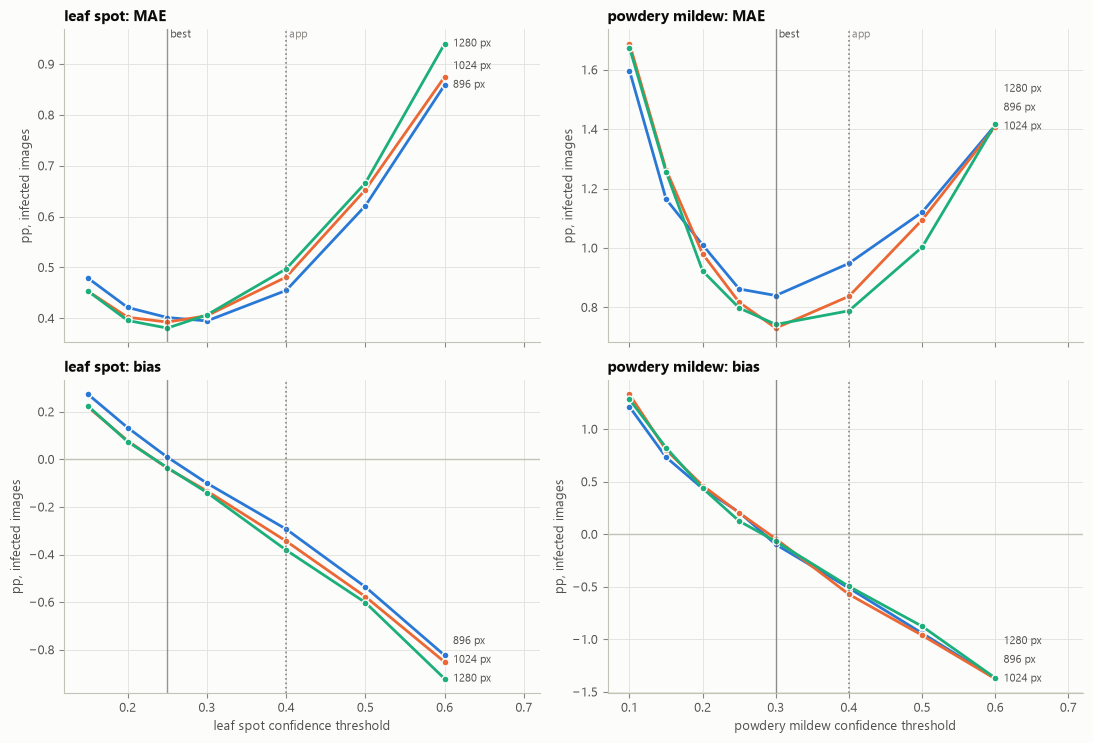

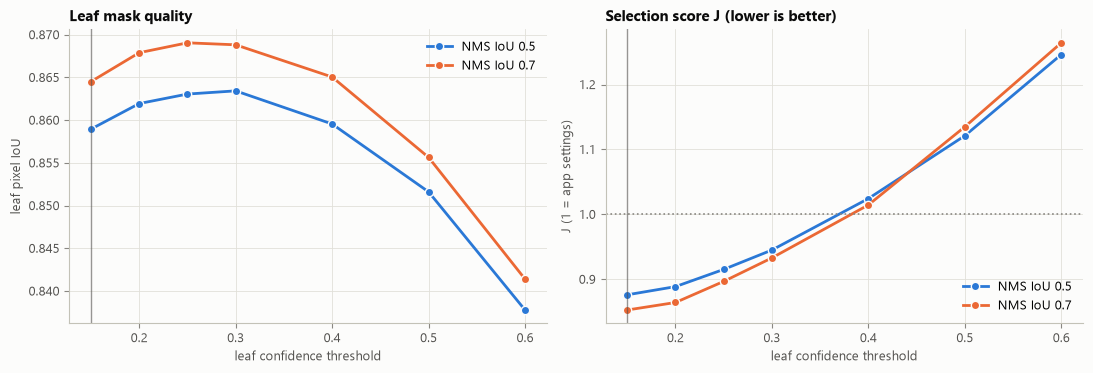

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex="col")
for col, (d, grid) in enumerate((("leaf_spot", SPOT_T), ("powdery_mildew", MILDEW_T))):
    for row_i, key in enumerate(("mae_pos", "bias_pos")):
        ax = axes[row_i][col]
        if key == "bias_pos":
            ax.axhline(0, color=AXIS, linewidth=1)
        ends = []
        for s_i, imgsz in enumerate(IMGSZS):
            ys = [find(results, {**BEST_SETTINGS, "imgsz": imgsz, d: t})["m"][d][key] for t in grid]
            ax.plot(grid, ys, marker="o", markersize=5, color=SERIES[s_i], markeredgecolor=SURFACE)
            ends.append((ys[-1], f"{imgsz} px"))
        end_labels(ax, grid[-1], ends, 0.06 * np.ptp(ax.get_ylim()))
        ax.axvline(BEST_SETTINGS[d], color=INK2, linestyle="-", linewidth=1, alpha=0.6)
        ax.axvline(APP[d], color=MUTED, linestyle=":", linewidth=1.2)
        ax.set_xlim(grid[0] - 0.03, grid[-1] + 0.12)
        ax.set_ylabel("pp, infected images")
        ax.set_title(f"{LABEL[d]}: {'MAE' if key == 'mae_pos' else 'bias'}")
    axes[1][col].set_xlabel(f"{LABEL[d]} confidence threshold")
    axes[0][col].text(BEST_SETTINGS[d], axes[0][col].get_ylim()[1], " best", va="top", color=INK2, fontsize=8)
    axes[0][col].text(APP[d], axes[0][col].get_ylim()[1], " app", va="top", color=MUTED, fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "disease_thresholds.png")
plt.show()

# Leaf threshold and NMS IoU: leaf IoU and J, other settings at the best values
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for i, iou in enumerate(IOUS):
    rows_ = [find(results, {**BEST_SETTINGS, "iou": iou, "leaf": t}) for t in LEAF_T]
    axes[0].plot(LEAF_T, [r["m"]["pixel"]["leaf"]["iou"] for r in rows_], marker="o", color=SERIES[i],
                 markeredgecolor=SURFACE, label=f"NMS IoU {iou}")
    axes[1].plot(LEAF_T, [r["J"] for r in rows_], marker="o", color=SERIES[i], markeredgecolor=SURFACE,
                 label=f"NMS IoU {iou}")
axes[0].set(xlabel="leaf confidence threshold", ylabel="leaf pixel IoU")
axes[0].set_title("Leaf mask quality")
axes[1].axhline(1, color=MUTED, linestyle=":", linewidth=1.2)
axes[1].set(xlabel="leaf confidence threshold", ylabel="J (1 = app settings)")
axes[1].set_title("Selection score J (lower is better)")
for ax in axes:
    ax.axvline(BEST_SETTINGS["leaf"], color=INK2, linewidth=1, alpha=0.6)
    ax.legend(loc="best")
fig.tight_layout()
fig.savefig(OUT / "leaf_threshold_nms.png")
plt.show()

## Final check on the test split (used once)

The app settings and the picked settings, on the same test images. 95 % CIs come from a bootstrap over test images; the **difference** (picked − app) uses the same resamples, so it is a paired comparison. If the difference CI includes 0, the improvement is not proven.

In [8]:
test = load_split("test", TEST_COCO_DIR)
print(len(test), "test images from", TEST_NAME)
TEST_C = {}
for name, s in (("app", APP), ("tuned", BEST_SETTINGS)):
    C, _ = sweep(test, s["imgsz"], s["iou"])
    TEST_C[name] = C[:, COMBOS.index((s["leaf"], s["leaf_spot"], s["powdery_mildew"]))]

rng = np.random.default_rng(SEED)
boots = [rng.integers(0, len(test), len(test)) for _ in range(N_BOOT)]
KEYS = [(d, k) for d in DISEASES for k in ("mae_pos", "bias_pos", "presence_f1")] + \
       [("pixel", c) for c in ("leaf", "leaf_spot", "powdery_mildew")]


def get(m, key):
    return m[key[0]][key[1]]["iou"] if key[0] == "pixel" else m[key[0]][key[1]]


point = {n: metrics(C) for n, C in TEST_C.items()}
boot_m = {n: [metrics(C[b]) for b in boots] for n, C in TEST_C.items()}


def ci(v):
    v = np.asarray(v, float)
    v = v[np.isfinite(v)]
    return np.percentile(v, [2.5, 97.5]) if len(v) else (np.nan, np.nan)


NAMES = {"mae_pos": "MAE, infected (pp)", "bias_pos": "bias, infected (pp)", "presence_f1": "presence F1"}
rows, summary = [], {}
for key in KEYS:
    label = f"{LABEL[key[1]]} pixel IoU" if key[0] == "pixel" else f"{LABEL[key[0]]} {NAMES[key[1]]}"
    a = np.array([get(m, key) for m in boot_m["app"]]); b = np.array([get(m, key) for m in boot_m["tuned"]])
    pa, pb = get(point["app"], key), get(point["tuned"], key)
    lo, hi = ci(b - a)
    rows.append([label, f"{pa:.3f} [{ci(a)[0]:.3f}, {ci(a)[1]:.3f}]", f"{pb:.3f} [{ci(b)[0]:.3f}, {ci(b)[1]:.3f}]",
                 f"{pb - pa:+.3f} [{lo:+.3f}, {hi:+.3f}]"])
    summary[label] = {"app": float(pa), "tuned": float(pb), "diff_ci95": [float(lo), float(hi)]}
print("app settings:  ", APP)
print("tuned settings:", BEST_SETTINGS)
show_table(f"Test split ({len(test)} images), point [95 % CI]", ["metric", "app", "tuned", "tuned − app"], rows)

loading annotations into memory...
Done (t=0.02s)
creating index...
index created!


76 test images from lds_v1-v2


app settings:   {'imgsz': 1024, 'iou': 0.7, 'leaf': 0.5, 'leaf_spot': 0.4, 'powdery_mildew': 0.4}
tuned settings: {'imgsz': 1280, 'iou': 0.7, 'leaf': 0.15, 'leaf_spot': 0.25, 'powdery_mildew': 0.3}

Test split (76 images), point [95 % CI]
metric                              app                     tuned                   tuned − app            
----------------------------------  ----------------------  ----------------------  -----------------------
leaf spot MAE, infected (pp)        0.483 [0.341, 0.659]    0.337 [0.209, 0.520]    -0.147 [-0.235, -0.073]
leaf spot bias, infected (pp)       -0.074 [-0.312, 0.112]  -0.128 [-0.342, 0.024]  -0.053 [-0.165, +0.053]
leaf spot presence F1               0.957 [0.917, 0.986]    0.971 [0.941, 0.993]    +0.015 [+0.000, +0.038]
powdery mildew MAE, infected (pp)   1.146 [0.677, 1.684]    1.297 [0.684, 2.119]    +0.151 [-0.185, +0.561]
powdery mildew bias, infected (pp)  -0.241 [-0.956, 0.462]  0.460 [-0.350, 1.370]   +0.701 [+0.282, +1.220]
powde

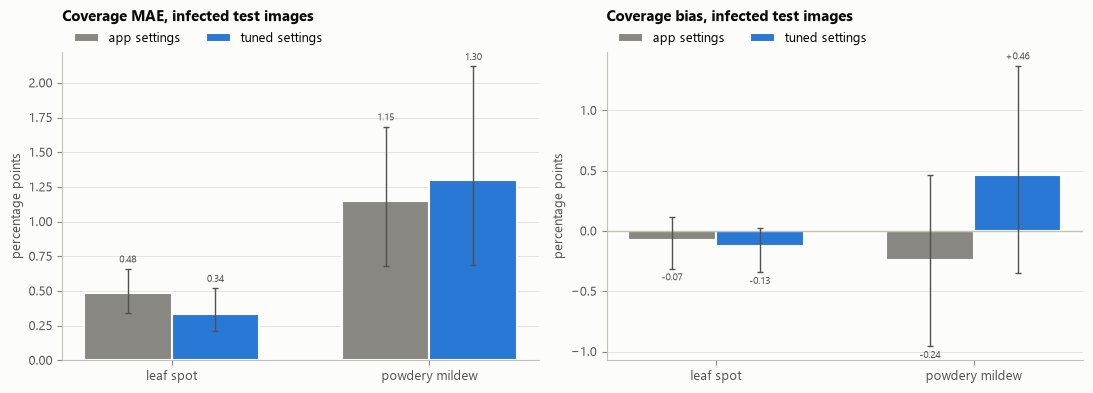

In [9]:
# Test comparison chart: MAE and |bias| on infected images per disease, app vs tuned, with 95 % CIs
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (key, title) in zip(axes, (("mae_pos", "Coverage MAE, infected test images"),
                                   ("bias_pos", "Coverage bias, infected test images"))):
    x = np.arange(len(DISEASES))
    for j, (name, color) in enumerate((("app", MUTED), ("tuned", SERIES[0]))):
        vals = np.array([point[name][d][key] for d in DISEASES])
        lo_hi = np.array([ci([m[d][key] for m in boot_m[name]]) for d in DISEASES])
        bars = ax.bar(x + (j - 0.5) * 0.34, vals, 0.34, color=color, edgecolor=SURFACE, linewidth=1.5,
                      label="app settings" if name == "app" else "tuned settings", zorder=2)
        ax.errorbar(x + (j - 0.5) * 0.34, vals, yerr=np.abs(lo_hi.T - vals), fmt="none", ecolor=INK2, elinewidth=1,
                    capsize=2, zorder=3)
        for b_, v, (lo, hi) in zip(bars, vals, lo_hi):
            # label just past the whisker, above for positive bars and below for negative ones
            y, dy, va = (hi, 3, "bottom") if v >= 0 else (lo, -3, "top")
            ax.annotate(f"{v:+.2f}" if key == "bias_pos" else f"{v:.2f}", (b_.get_x() + b_.get_width() / 2, y),
                        xytext=(0, dy), textcoords="offset points", ha="center", va=va, fontsize=7.5, color=INK2)
    if key == "bias_pos":
        ax.axhline(0, color=AXIS, linewidth=1)
    ax.set(xticks=x, xticklabels=[LABEL[d] for d in DISEASES], ylabel="percentage points")
    ax.grid(axis="x", visible=False)
    ax.set_title(title, pad=22)
    ax.legend(ncols=2, loc="upper left", bbox_to_anchor=(0, 1.1))
fig.tight_layout()
fig.savefig(OUT / "test_app_vs_tuned.png")
plt.show()

## Visual test

Pictures with the settings you want to try, next to the app's current settings, so the difference can be judged by eye.
- **Test images (with labels):** photo, labels, prediction with the app settings, prediction with `VISUAL`, and an error map for `VISUAL` (red = labelled disease missed, yellow = disease predicted where there is none).
  Shown: the test image with the most mildew, the one with the most leaf spot, and `N_RANDOM` random ones.
- **Your own photos (no labels):** the two predictions side by side, with the coverage the app would report (whole image).

Edit `VISUAL` to try other values; this block reuses the loaded model, so it runs in seconds.

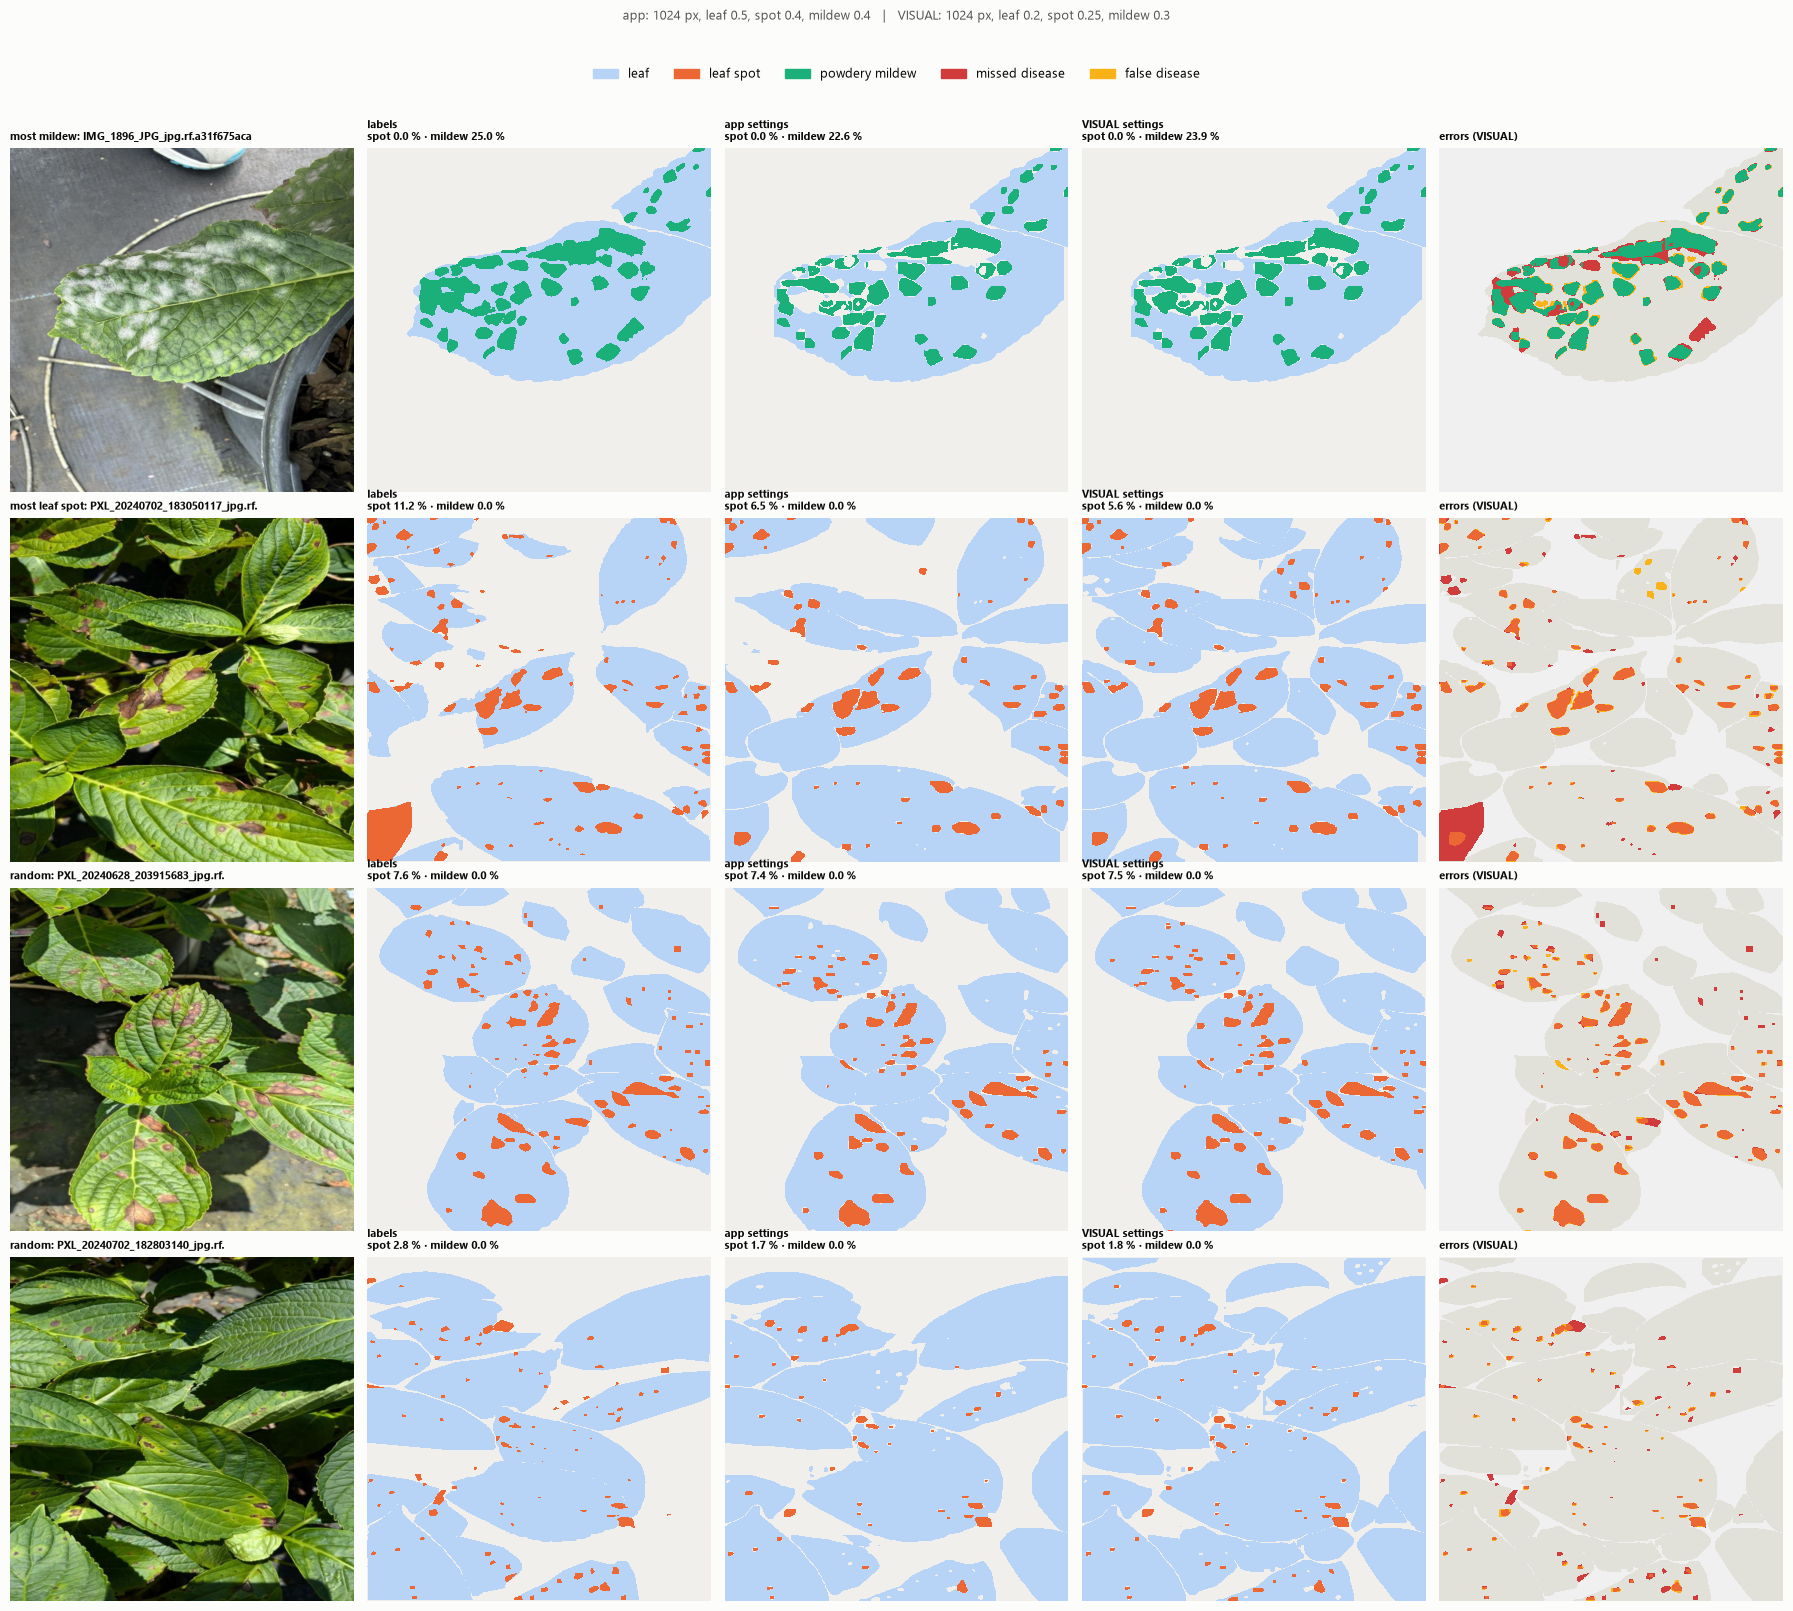

In [10]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from eval_utils import image_coverage

VISUAL = {"imgsz": 1024, "iou": 0.7, "leaf": 0.2, "leaf_spot": 0.25, "powdery_mildew": 0.3}
N_RANDOM = 2
PHOTOS = [Path(r"C:\Users\bp67339\Downloads\test4.webp")]  # unlabelled photos; add paths here

MAP_COLORS = ListedColormap(["#f0efec", "#b7d3f6", SERIES[1], SERIES[2]])  # background, leaf, leaf spot, mildew
MISSED, FALSE = "#d03b3b", "#fab219"
hexrgb = lambda h: tuple(int(h[k:k + 2], 16) for k in (1, 3, 5))


def predict_map(path, shape, s):
    # Class map for one image with settings s (imgsz, iou, leaf / leaf_spot / powdery_mildew thresholds)
    r = model.predict(str(path), imgsz=s["imgsz"], iou=s["iou"], conf=0.01, retina_masks=True, verbose=False, device=0)[0]
    pmap = torch.zeros(shape, dtype=torch.long, device=DEVICE)
    if r.masks is not None:
        masks, cls, conf = r.masks.data.bool(), r.boxes.cls, r.boxes.conf
        pmap[unions(masks, cls, conf, CLS_ID["leaf"], (s["leaf"],))[0]] = LEAF_ID
        pmap[unions(masks, cls, conf, CLS_ID["powdery_mildew"], (s["powdery_mildew"],))[0]] = MILDEW_ID
        pmap[unions(masks, cls, conf, CLS_ID["leaf_spot"], (s["leaf_spot"],))[0]] = SPOT_ID
    return pmap.cpu().numpy().astype(np.uint8)


def error_map(g_map, p_map):
    rgb = np.full(g_map.shape + (3,), 0xf0, np.uint8)
    rgb[(g_map > 0) | (p_map > 0)] = (0xe1, 0xe0, 0xd9)  # leaf area
    for cls in (SPOT_ID, MILDEW_ID):
        rgb[(g_map == cls) & (p_map == cls)] = hexrgb(SERIES[1] if cls == SPOT_ID else SERIES[2])
    rgb[(g_map >= SPOT_ID) & (p_map != g_map)] = hexrgb(MISSED)
    rgb[(p_map >= SPOT_ID) & (g_map < SPOT_ID)] = hexrgb(FALSE)
    return rgb


def cov_text(cmap):
    c = image_coverage(cmap)
    return "no leaf" if not c else f"spot {c['leaf_spot']:.1f} % · mildew {c['powdery_mildew']:.1f} %"


def settings_text(s):
    return f"{s['imgsz']} px, leaf {s['leaf']}, spot {s['leaf_spot']}, mildew {s['powdery_mildew']}"


gt_cov = [image_coverage(g) for _, g in test]
by_true = lambda d: max(range(len(test)), key=lambda i: (gt_cov[i] or {d: 0})[d])
rand = np.random.default_rng(SEED).choice(len(test), N_RANDOM, replace=False).tolist()
picks = list(dict.fromkeys([by_true("powdery_mildew"), by_true("leaf_spot"), *rand]))
tags = {by_true("powdery_mildew"): "most mildew", by_true("leaf_spot"): "most leaf spot"}

fig, axes = plt.subplots(len(picks), 5, figsize=(18, 3.9 * len(picks)), squeeze=False)
for axr, i in zip(axes, picks):
    path, g_map = test[i]
    app_map, vis_map = predict_map(path, g_map.shape, APP), predict_map(path, g_map.shape, VISUAL)
    axr[0].imshow(Image.open(path).convert("RGB")); axr[0].set_title(f"{tags.get(i, 'random')}: {path.name[:30]}", fontsize=8)
    for ax, m, title in ((axr[1], g_map, "labels"), (axr[2], app_map, "app settings"), (axr[3], vis_map, "VISUAL settings")):
        ax.imshow(m, cmap=MAP_COLORS, vmin=0, vmax=3, interpolation="nearest")
        ax.set_title(f"{title}\n{cov_text(m)}", fontsize=8)
    axr[4].imshow(error_map(g_map, vis_map), interpolation="nearest"); axr[4].set_title("errors (VISUAL)", fontsize=8)
    for ax in axr:
        ax.axis("off")
fig.legend(handles=[Patch(color="#b7d3f6", label="leaf"), Patch(color=SERIES[1], label="leaf spot"),
                    Patch(color=SERIES[2], label="powdery mildew"), Patch(color=MISSED, label="missed disease"),
                    Patch(color=FALSE, label="false disease")], loc="upper center", ncols=5, bbox_to_anchor=(0.5, 1.0))
fig.suptitle(f"app: {settings_text(APP)}   |   VISUAL: {settings_text(VISUAL)}", y=1.03, fontsize=9, color=INK2)
fig.tight_layout(rect=(0, 0, 1, 0.98))
fig.savefig(OUT / "visual_test_images.png", dpi=110)
plt.show()

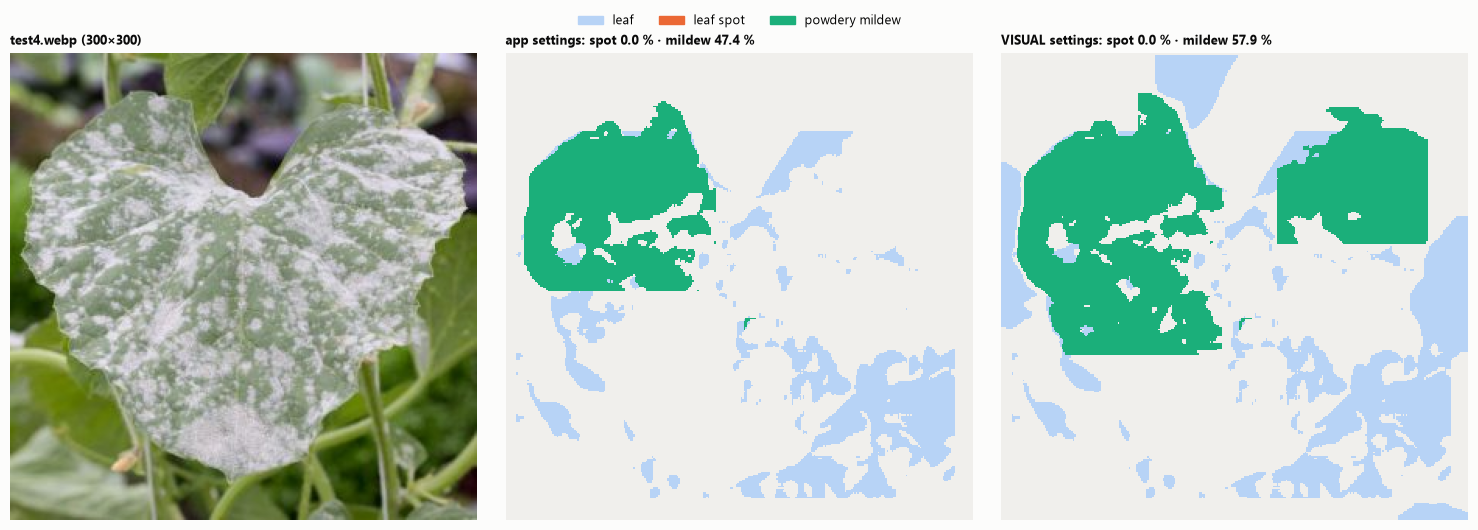

In [11]:
# Unlabelled photos: the same two predictions side by side
for path in PHOTOS:
    image = Image.open(path).convert("RGB")
    shape = (image.height, image.width)
    app_map, vis_map = predict_map(path, shape, APP), predict_map(path, shape, VISUAL)
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
    axes[0].imshow(image); axes[0].set_title(f"{path.name} ({image.width}×{image.height})", fontsize=9)
    for ax, m, title in ((axes[1], app_map, "app settings"), (axes[2], vis_map, "VISUAL settings")):
        ax.imshow(m, cmap=MAP_COLORS, vmin=0, vmax=3, interpolation="nearest")
        ax.set_title(f"{title}: {cov_text(m)}", fontsize=9)
    for ax in axes:
        ax.axis("off")
    fig.legend(handles=[Patch(color="#b7d3f6", label="leaf"), Patch(color=SERIES[1], label="leaf spot"),
                        Patch(color=SERIES[2], label="powdery mildew")], loc="upper center", ncols=3, bbox_to_anchor=(0.5, 1.02))
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(OUT / f"visual_test_{path.stem}.png", dpi=110)
    plt.show()

## Save and apply

`settings.json` holds the picked settings, the validation ranking and the test comparison.

To use the settings in the app:
- **Thresholds:** set `LEAF_CONFIDENCE` and `DISEASE_CONFIDENCE` in `backend/.env`. The backend has **one** disease threshold today. If the picked spot and mildew thresholds differ, either use the mildew one for both (check its spot numbers in the validation table) or add per-disease thresholds to `backend/app/config.py` and `filter_predictions`.
- **Input size:** if `imgsz` is not 1024, re-export with that size in `04_export` (the ONNX input size is fixed at export).
- **NMS IoU:** if it is not 0.7, the same value must be used in the backend's NMS.

Then report the test table above in the paper, together with the sentence: *"Inference settings were selected on the validation split and fixed before evaluation on the test split."*

In [12]:
(OUT / "settings.json").write_text(json.dumps({
    "checkpoint": str(CHECKPOINT.relative_to(ROOT)), "data": DATA_NAME, "test_data": TEST_NAME, "selection": "valid", "rule":
    "min mean_d(MAE_pos_d / MAE_pos_d at app settings), presence F1 drop <= %.2f, ties by sum |bias|" % F1_DROP,
    "app": APP, "tuned": BEST_SETTINGS,
    "valid_top10": [dict(zip(HEADER[1:], [float(v) if isinstance(v, (float, np.floating)) else v for v in row(r)[1:]]))
                    for r in allowed[:10]],
    "test": summary,
}, indent=1))
print("saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")

saved:
  disease_thresholds.png
  leaf_threshold_nms.png
  settings.json
  test_app_vs_tuned.png
  visual_test_images.png
  visual_test_test4.png
